# Correctness Verification

We check that our pipeline recovers the expected Betti numbers on the four synthetic datasets, and compare each persistence diagram with the one produced by Ripser on the same point cloud.

This notebook executes the pipeline directly: the datasets are small, so the computation is fast and the result is best seen visually.

## 1. Setup

In [1]:
import matplotlib.pyplot as plt
from ripser import ripser

from persistent_homology import compute_persistence
from persistent_homology.plotting import plot_persistence_diagram, ripser_to_diagram
from datasets.synthetic import make_circle, make_sphere, make_torus, make_cube

## 2. Helpers

In [6]:
def betti_at(diagram, eps, max_dim=2):
    """Count features alive at filtration value eps."""
    counts = {k: 0 for k in range(max_dim + 1)}
    for dim, intervals in diagram.items():
        if dim > max_dim:
            continue
        for (b, d) in intervals:
            if b <= eps and (d == float('inf') or d > eps):
                counts[dim] += 1
    return counts


def compare(points, max_dim, max_eps, annotations=None,
            name='', algorithm='cohomology', figprefix=None,
            split=False):
    """Compute our diagram and Ripser's, then plot them side by side.

    Parameters
    ----------
    points : ndarray
        The point cloud.
    max_dim : int
        Highest homology dimension to display.
    max_eps : float
        Maximum filtration value.
    annotations : list of dict, optional
        Annotations applied to our diagram (not to Ripser's).
    name : str
        Figure title, shown above the combined side-by-side plot.
    algorithm : str
        One of {'standard', 'clearing', 'cohomology'}.
    figprefix : str, optional
        File name prefix (without extension) for saved figures, written
        under "../figures/".
    split : bool, optional
        When True, in addition to the combined side-by-side figure,
        save each diagram on its own as "{figprefix}_ours.png" and
        "{figprefix}_ripser.png". The two extra files share the
        appearance of the combined plot and are not displayed in the
        notebook; they are only saved to disk. Requires "figprefix".

    Returns
    -------
    ours, theirs : dict
        The two diagrams.
    """
    ours = compute_persistence(points, max_dim=max_dim + 1,
                               max_eps=max_eps, algorithm=algorithm)
    ours = {d: ivs for d, ivs in ours.items() if d <= max_dim}
    res = ripser(points, maxdim=max_dim, thresh=max_eps)
    theirs = ripser_to_diagram(res)

    # Combined side-by-side figure.
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    plot_persistence_diagram(ours, max_dim=max_dim,
                             annotations=annotations,
                             title='Our implementation', ax=axes[0])
    plot_persistence_diagram(theirs, max_dim=max_dim,
                             title='Ripser', ax=axes[1])
    fig.suptitle(name)
    plt.tight_layout()
    if figprefix:
        fig.savefig(f'../figures/{figprefix}.png', dpi=150,
                    bbox_inches='tight')
    plt.show()

    if split and figprefix:
        plot_persistence_diagram(
            ours, max_dim=max_dim, annotations=annotations,
            title= '',  # 'Our implementation',
            savepath=f'../figures/{figprefix}_ours.png',
        )
        plt.close()
        plot_persistence_diagram(
            theirs, max_dim=max_dim,
            title= '',  # 'Ripser',
            savepath=f'../figures/{figprefix}_ripser.png',
        )
        plt.close()

    return ours, theirs

## 3. Circle $S^1$

Expected: $\beta_0 = 1$, $\beta_1 = 1$.

Filtration built with 1227 simplices.


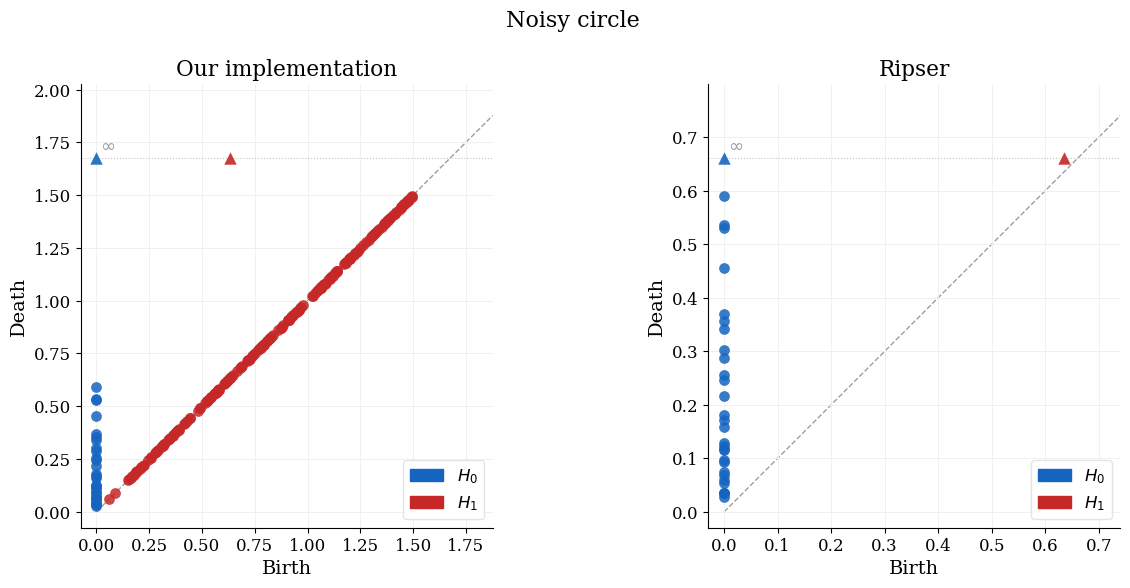

Saved -> ../figures/circle_ours.png
Saved -> ../figures/circle_ripser.png
betti numbers: {0: 1, 1: 1}


In [7]:
points = make_circle(n=30)
ours, _ = compare(points, max_dim=1, max_eps=1.5,
                  annotations=[{'dim': 1, 'xy': None,
                                'text': 'the loop\n(essential)'}]
                  if False else None,
                  name='Noisy circle', split=True, figprefix='circle')
print('betti numbers:', betti_at(ours, 1.5, 1))

## 4. Sphere $S^2$

Expected: $\beta_0 = 1$, $\beta_1 = 0$, $\beta_2 = 1$.

Filtration built with 295275 simplices.


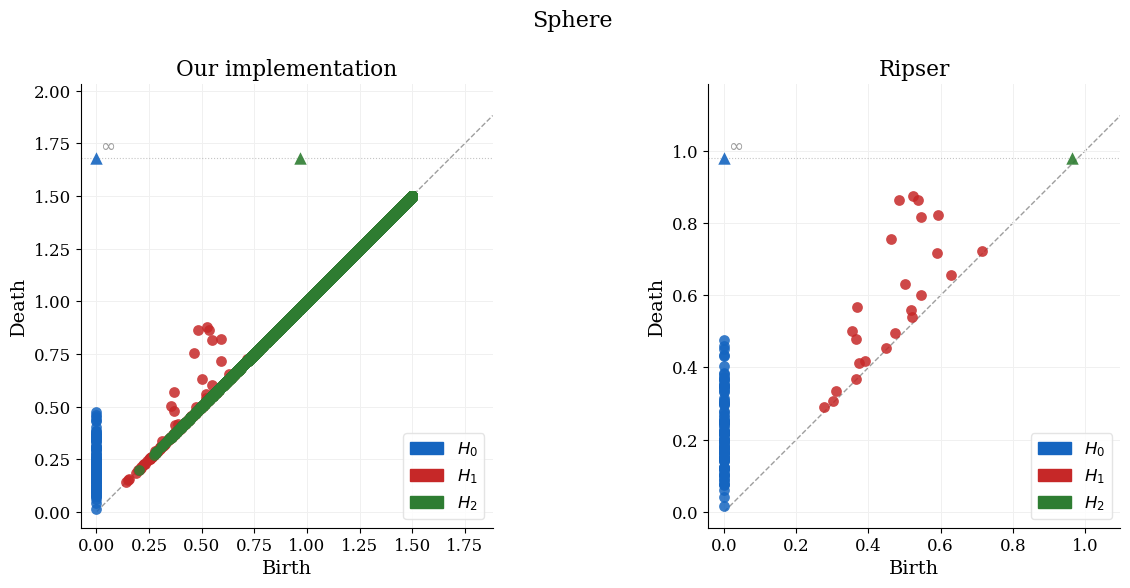

Saved -> ../figures/sphere_ours.png
Saved -> ../figures/sphere_ripser.png
betti numbers: {0: 1, 1: 0, 2: 1}


In [8]:
points = make_sphere(n=100)
ours, _ = compare(points, max_dim=2, max_eps=1.5,
                  name='Sphere', split=True, figprefix='sphere')
print('betti numbers:', betti_at(ours, 1.5, 2))

## 5. Torus $T^2$

Expected: $\beta_0 = 1$, $\beta_1 = 2$, $\beta_2 = 1$.

Filtration built with 7902 simplices.


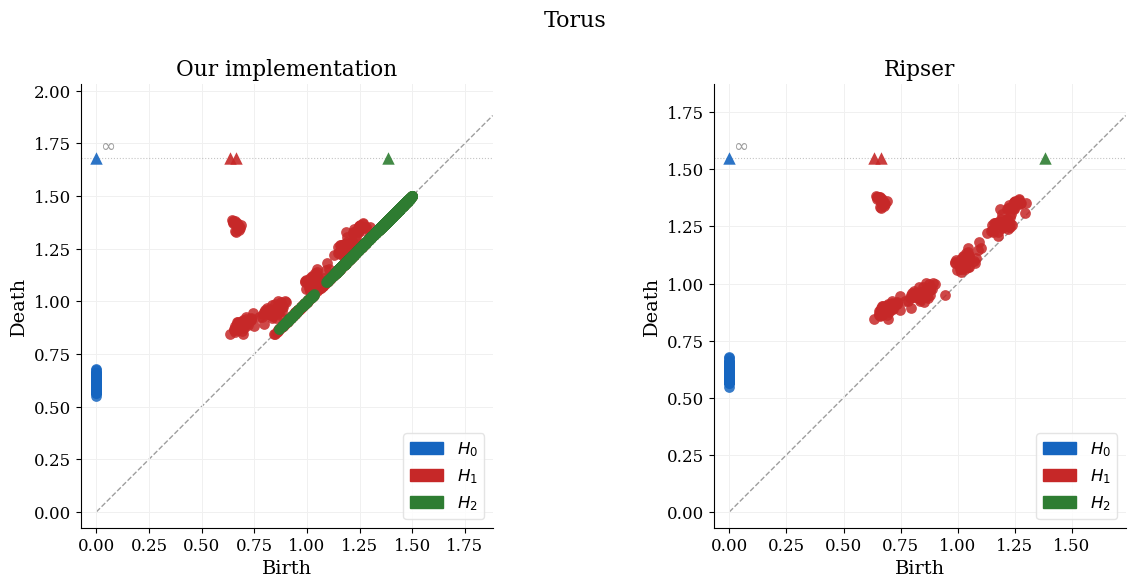

Saved -> ../figures/torus_ours.png
Saved -> ../figures/torus_ripser.png
betti numbers: {0: 1, 1: 2, 2: 1}


In [9]:
points = make_torus(n_u=20, n_v=10)
ours, _ = compare(points, max_dim=2, max_eps=1.5,
                  name='Torus', split=True, figprefix='torus')
print('betti numbers:', betti_at(ours, 1.5, 2))

## 6. Random cube $[0,1]^3$

Expected: $\beta_0 = 1$, $\beta_1 = 0$, $\beta_2 = 0$ (a contractible space).

Filtration built with 4083123 simplices.


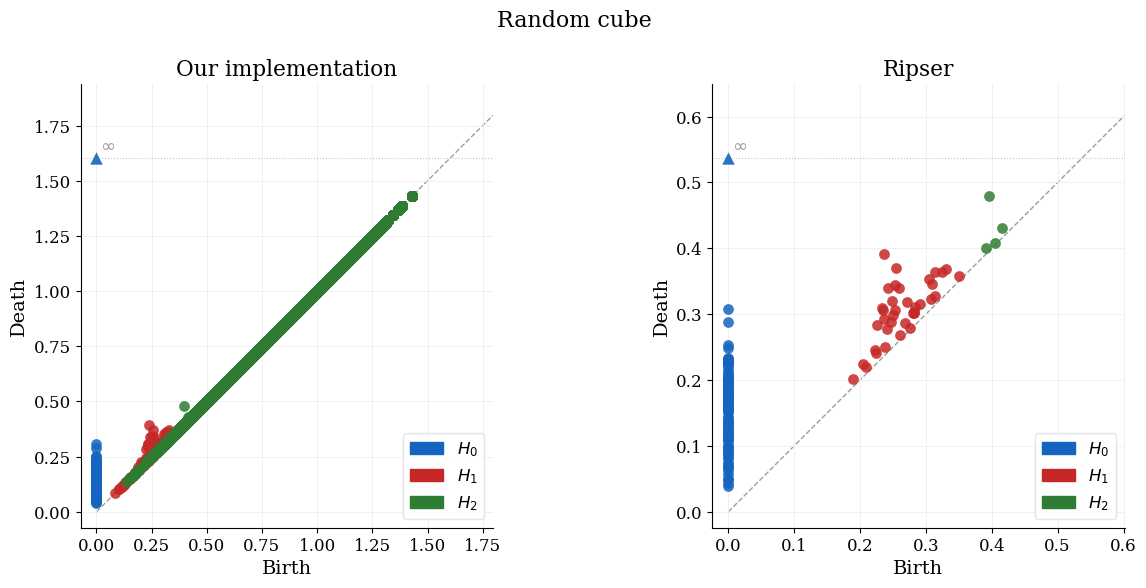

Saved -> ../figures/cube_ours.png
Saved -> ../figures/cube_ripser.png
betti numbers: {0: 1, 1: 0, 2: 0}


In [10]:
points = make_cube(n=100)
ours, _ = compare(points, max_dim=2, max_eps=1.5,
                  name='Random cube', split=True, figprefix='cube')
print('betti numbers:', betti_at(ours, 1.5, 2))